# 02. Limpeza, Pré-Processamento e Seleção de Variáveis (Regressão e Classificação)
**Disciplina:** DCT1401 - Inteligência Artificial  
**Dataset:** Food Delivery Orders and ETA Logistics Dataset  

Este notebook executa de forma rigorosa todas as etapas de preparação dos dados e definição formal dos problemas de **Regressão** e **Classificação**, atendendo integralmente às diretrizes da disciplina:

1. **Tratamento de Valores Ausentes com Justificativa por Coluna:** Exclusão fundamentada de `cancellation_reason` ($98{,}26\%$ ausente e informação pós-evento) e filtragem dos $868$ pedidos cancelados (`order_status == 'Cancelled'`), que concentram $100\%$ dos nulos de `actual_delivery_time_minutes`, `late_delivery`, `tip_amount` e `customer_rating`.
2. **Especificação Matemática do Tratamento de Outliers (*Winsorization* / *Capping*):** Formulação explícita $y_i^* = \min(y_i, 120{,}0)$ aplicada à variável `actual_delivery_time_minutes`, quantificando exatamente os registros truncados e preservando a ocorrência operacional de entregas demoradas sem distorcer a escala original em minutos.
3. **Prevenção de Vazamento de Dados (*Data Leakage*) e Eliminação de Multicolinearidade:**
   - Remoção das variáveis pós-entrega indisponíveis no momento do pedido (`customer_rating`, `tip_amount`, `order_status`, `cancellation_reason`).
   - Eliminação das variáveis financeiras redundantes (`subtotal`, `tax_amount`, `service_fee`), que apresentam correlação $r > 0{,}94$ entre si, mantendo apenas `order_total` como representante financeiro.
4. **Codificação de Variáveis Categóricas:** Aplicação de *One-Hot Encoding* (`drop_first=True`) sobre `weather`, `traffic_level`, `customer_type` e `day_of_week`.
5. **Definição e Análise Estatística do Problema de Regressão:**
   - **Alvo:** `actual_delivery_time_minutes` (em minutos reais).
   - **Features vs. Alvo (no conjunto de treino):** Tabela de Correlação de Pearson ($r$) e Estatística $F$ (`f_regression` com $p$-valor), além de gráficos de dispersão/regressão das principais features contra o alvo.
6. **Definição e Análise Estatística do Problema de Classificação:**
   - **Alvo Natural do Domínio:** `late_delivery` ($1 = \text{Atrasado}$, $0 = \text{No Prazo}$), substituindo o critério arbitrário da mediana e analisando o balanceamento real das classes ($63{,}43\%$ No Prazo vs. $36{,}57\%$ Atrasado).
   - **Features vs. Alvo (no conjunto de treino):** Testes estatísticos **ANOVA $F$ (`f_classif`)** para variáveis contínuas/discretas e **Qui-Quadrado ($\chi^2$)** para variáveis categóricas/binárias, acompanhados de *boxplots* por classe e gráficos de proporção.
7. **Padronização Sem Vazamento de Dados (*Pipeline*):** Divisão Treino ($80\%$) / Teste ($20\%$) com `random_state=42` (e `stratify=y` na classificação) **antes** do ajuste do `StandardScaler` em `Pipeline`, e exportação dos conjuntos prontos (`dataset_regression.csv`, `dataset_classification.csv`, `dataset_clean.csv` e `dataset_preprocessed.csv`).


## 1. Carregamento da Base Bruta e Tratamento de Valores Ausentes por Coluna
Abaixo carregamos a base original (`50.000` registros e `37` colunas) e documentamos a decisão técnica tomada para cada uma das 5 colunas que apresentam valores ausentes:

In [1]:
from IPython.display import display
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

sys.path.append("..")
from src.preprocessing import (
    clean_raw_dataset,
    prepare_modeling_datasets,
    compute_regression_feature_stats,
    compute_classification_feature_stats,
    build_preprocessing_pipeline,
    ID_AND_TEXT_COLS,
    POST_DELIVERY_LEAKAGE_COLS,
    COLLINEAR_FINANCIAL_COLS
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../models", exist_ok=True)
os.makedirs("../reports/figures", exist_ok=True)
os.makedirs("../reports/tables", exist_ok=True)

df_bruto = pd.read_csv("../data/raw/food_delivery_orders_dataset.csv")
print(f"Dimensões da base bruta: {df_bruto.shape[0]:,} linhas x {df_bruto.shape[1]} colunas.")

# Tabela de justificativa coluna a coluna para os valores ausentes
justificativa_ausentes = pd.DataFrame([
    {
        "Coluna": "cancellation_reason",
        "Nulos": int(df_bruto["cancellation_reason"].isnull().sum()),
        "%_Nulos": round(df_bruto["cancellation_reason"].isnull().mean() * 100, 2),
        "Acao_Adotada": "Remoção da coluna (Drop Column)",
        "Justificativa_Tecnica": "Ausente em 98,26% da base (todos os pedidos entregues) e representa evento pós-cancelamento."
    },
    {
        "Coluna": "actual_delivery_time_minutes",
        "Nulos": int(df_bruto["actual_delivery_time_minutes"].isnull().sum()),
        "%_Nulos": round(df_bruto["actual_delivery_time_minutes"].isnull().mean() * 100, 2),
        "Acao_Adotada": "Remoção das 868 linhas canceladas",
        "Justificativa_Tecnica": "Variável alvo de regressão; nula exclusivamente nos 868 pedidos cancelados (sem entrega física)."
    },
    {
        "Coluna": "late_delivery",
        "Nulos": int(df_bruto["late_delivery"].isnull().sum()),
        "%_Nulos": round(df_bruto["late_delivery"].isnull().mean() * 100, 2),
        "Acao_Adotada": "Remoção das 868 linhas canceladas",
        "Justificativa_Tecnica": "Variável alvo de classificação; nula exclusivamente nos 868 pedidos cancelados."
    },
    {
        "Coluna": "tip_amount",
        "Nulos": int(df_bruto["tip_amount"].isnull().sum()),
        "%_Nulos": round(df_bruto["tip_amount"].isnull().mean() * 100, 2),
        "Acao_Adotada": "Remoção das 868 linhas + Exclusão por Leakage",
        "Justificativa_Tecnica": "Nula nos pedidos cancelados e definida/ajustada após o desfecho da entrega."
    },
    {
        "Coluna": "customer_rating",
        "Nulos": int(df_bruto["customer_rating"].isnull().sum()),
        "%_Nulos": round(df_bruto["customer_rating"].isnull().mean() * 100, 2),
        "Acao_Adotada": "Remoção das 868 linhas + Exclusão por Leakage",
        "Justificativa_Tecnica": "Avaliação atribuída pelo cliente após receber o pedido (forte vazamento de dados: r = -0,67 com atraso)."
    }
])

print("=== JUSTIFICATIVA TÉCNICA POR COLUNA PARA VALORES AUSENTES ===")
display(justificativa_ausentes)


Dimensões da base bruta: 50,000 linhas x 37 colunas.
=== JUSTIFICATIVA TÉCNICA POR COLUNA PARA VALORES AUSENTES ===


,Coluna,Nulos,%_Nulos,Acao_Adotada,Justificativa_Tecnica
0,cancellation_reason,49132,98.26,Remoção da coluna (Drop Column),"Ausente em 98,26% da base (todos os pedidos en..."
1,actual_delivery_time_minutes,868,1.74,Remoção das 868 linhas canceladas,Variável alvo de regressão; nula exclusivament...
2,late_delivery,868,1.74,Remoção das 868 linhas canceladas,Variável alvo de classificação; nula exclusiva...
3,tip_amount,868,1.74,Remoção das 868 linhas + Exclusão por Leakage,Nula nos pedidos cancelados e definida/ajustad...
4,customer_rating,868,1.74,Remoção das 868 linhas + Exclusão por Leakage,Avaliação atribuída pelo cliente após receber ...


## 2. Especificação do Tratamento de Outliers (*Winsorization* / *Capping*) e Verificação de Anomalias
Na variável alvo de regressão (`actual_delivery_time_minutes`), o método IQR identificou $1.657$ registros acima de $67{,}50$ minutos, chegando até $172{,}00$ minutos.
- **Por que não excluir esses registros?** Entregas entre $68$ e $120$ minutos correspondem a cenários operacionais legítimos (tempestades, trânsito severo e horários de pico com alta distância). Excluí-las enviesaria os modelos a subestimar sistematicamente os cenários críticos.
- **Transformação Matemática Aplicada (*Winsorization* unilateral superior em $T_{\max} = 120{,}0$ min):**
$$y_i^* = \min(y_i,\; 120{,}0)$$
Apenas os valores extremos acima de $2$ horas ($120$ minutos) são truncados no teto operacional de $120{,}0$ minutos, mantendo a unidade original em minutos para interpretação direta do MAE e do RMSE. Também verificamos formalmente a existência de valores negativos inválidos nas variáveis numéricas.

Registros concluídos (order_status == 'Completed'): 49,132 linhas.
Total de valores ausentes remanescentes em df_limpo: 0
Registros truncados pelo Capping (> 120 min): 32 (0.07% dos entregues)
Tempo máximo antes do Capping: 172.0 min | Após Capping: 120.0 min
Total de valores negativos encontrados nas 20 colunas numéricas: 0


Arquivo '../data/processed/dataset_clean.csv' salvo com sucesso!


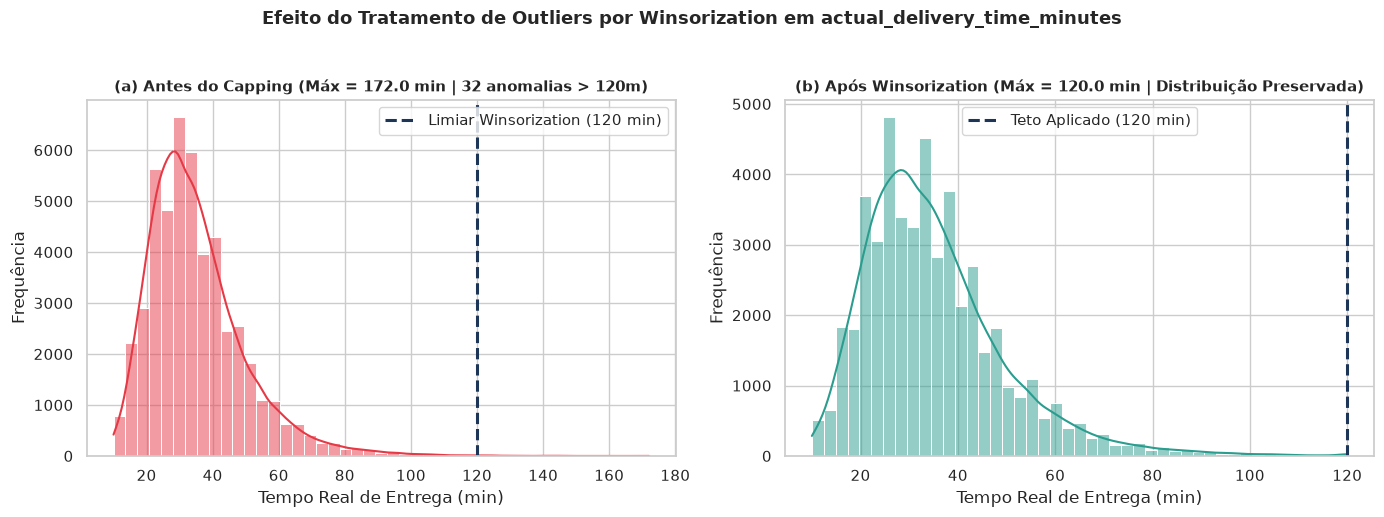

In [2]:
# Contagem de registros acima de 120 min antes do capping
df_entregues_raw = df_bruto.dropna(subset=["actual_delivery_time_minutes", "late_delivery"])
qtd_acima_120 = (df_entregues_raw["actual_delivery_time_minutes"] > 120.0).sum()
pct_acima_120 = (qtd_acima_120 / len(df_entregues_raw)) * 100
max_antes = df_entregues_raw["actual_delivery_time_minutes"].max()

# Aplicação da função padronizada de limpeza
df_limpo = clean_raw_dataset(df_bruto, max_delivery_minutes=120.0)
max_depois = df_limpo["actual_delivery_time_minutes"].max()

print(f"Registros concluídos (order_status == 'Completed'): {len(df_limpo):,} linhas.")
print(f"Total de valores ausentes remanescentes em df_limpo: {df_limpo.isnull().sum().sum()}")
print(f"Registros truncados pelo Capping (> 120 min): {qtd_acima_120} ({pct_acima_120:.2f}% dos entregues)")
print(f"Tempo máximo antes do Capping: {max_antes:.1f} min | Após Capping: {max_depois:.1f} min")

# Verificação de valores negativos em todas as colunas numéricas
num_cols = df_limpo.select_dtypes(include=[np.number]).columns
negativos = (df_limpo[num_cols] < 0).sum()
print(f"Total de valores negativos encontrados nas {len(num_cols)} colunas numéricas: {negativos.sum()}")

# Salvando dataset_clean.csv (com variáveis originais limpas, usado também pelo Sistema Especialista)
df_limpo.to_csv("../data/processed/dataset_clean.csv", index=False)
print("Arquivo '../data/processed/dataset_clean.csv' salvo com sucesso!")

# Visualização Gráfica do Efeito do Winsorization (Antes vs. Depois do Capping em 120 min)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_entregues_raw["actual_delivery_time_minutes"], bins=45, kde=True, color="#e63946", ax=axes[0])
axes[0].axvline(120.0, color="#1d3557", linestyle="--", lw=2.2, label="Limiar Winsorization (120 min)")
axes[0].set_title(f"(a) Antes do Capping (Máx = {max_antes:.1f} min | {qtd_acima_120} anomalias > 120m)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Tempo Real de Entrega (min)")
axes[0].set_ylabel("Frequência")
axes[0].legend()

sns.histplot(df_limpo["actual_delivery_time_minutes"], bins=45, kde=True, color="#2a9d8f", ax=axes[1])
axes[1].axvline(120.0, color="#1d3557", linestyle="--", lw=2.2, label="Teto Aplicado (120 min)")
axes[1].set_title(f"(b) Após Winsorization (Máx = {max_depois:.1f} min | Distribuição Preservada)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Tempo Real de Entrega (min)")
axes[1].set_ylabel("Frequência")
axes[1].legend()

plt.suptitle("Efeito do Tratamento de Outliers por Winsorization em actual_delivery_time_minutes", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("../reports/figures/preprocessing_winsorization.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Eliminação de Multicolinearidade, Prevenção de *Data Leakage* e Codificação Categórica
Na análise exploratória (Notebook 01), constatamos que:
1. **Bloco Financeiro Colinear:** `subtotal`, `tax_amount`, `service_fee` e `order_total` possuem correlações lineares entre $r = 0{,}9400$ e $r = 0{,}9971$. Para eliminar a redundância que distorce pesos lineares e dilui a importância de variáveis nas árvores, **descartamos `subtotal`, `tax_amount` e `service_fee`, mantendo exclusivamente `order_total`** (além de `items_count`, `delivery_fee` e `discount_percent`).
2. **Prevenção de *Data Leakage*:** Descartamos `customer_rating` e `tip_amount` (informações pós-entrega), `order_status` (constante igual a `'Completed'` nos pedidos entregues) e os identificadores (`order_id`, `customer_id`, `restaurant_id`, `driver_id`, timestamps e nomes geográficos brutos).
3. **Codificação *One-Hot Encoding* (`drop_first=True`):** Aplicada às variáveis categóricas nominais `weather`, `traffic_level`, `customer_type` e `day_of_week`. Diferentemente do *Label Encoding* (que imporia uma ordenação numérica artificial $0 < 1 < 2 < 3$ sobre categorias nominais como dias da semana ou tipos de cliente), o *One-Hot Encoding* cria variáveis indicadoras binárias ($0$ ou $1$) ortogonais.

In [3]:
df_encoded, df_regression, df_classification = prepare_modeling_datasets(df_limpo)

print(f"Colunas de ID/Texto removidas ({len(ID_AND_TEXT_COLS)}): {ID_AND_TEXT_COLS}")
print(f"Colunas de Data Leakage pós-entrega removidas ({len(POST_DELIVERY_LEAKAGE_COLS)}): {POST_DELIVERY_LEAKAGE_COLS}")
print(f"Colunas financeiras colineares removidas ({len(COLLINEAR_FINANCIAL_COLS)}): {COLLINEAR_FINANCIAL_COLS}")
print("-" * 80)
print(f"Dimensões de df_regression:     {df_regression.shape[0]:,} linhas x {df_regression.shape[1]} colunas (23 features + alvo 'actual_delivery_time_minutes')")
print(f"Dimensões de df_classification: {df_classification.shape[0]:,} linhas x {df_classification.shape[1]} colunas (23 features + alvo 'late_delivery')")

# Verificação da máxima correlação remanescente entre as features financeiras
corr_rem = df_regression[["order_total", "items_count", "delivery_fee", "discount_percent"]].corr()
print("\n=== MATRIZ DE CORRELAÇÃO DO BLOCO FINANCEIRO APÓS REMOÇÃO DE REDUNDÂNCIAS ===")
display(corr_rem.round(4))


Colunas de ID/Texto removidas (11): ['order_id', 'customer_id', 'restaurant_id', 'driver_id', 'order_timestamp', 'order_date', 'city', 'delivery_area', 'restaurant_type', 'restaurant_primary_category', 'payment_method']
Colunas de Data Leakage pós-entrega removidas (4): ['cancellation_reason', 'order_status', 'customer_rating', 'tip_amount']
Colunas financeiras colineares removidas (3): ['subtotal', 'tax_amount', 'service_fee']
--------------------------------------------------------------------------------
Dimensões de df_regression:     49,132 linhas x 27 colunas (23 features + alvo 'actual_delivery_time_minutes')
Dimensões de df_classification: 49,132 linhas x 27 colunas (23 features + alvo 'late_delivery')

=== MATRIZ DE CORRELAÇÃO DO BLOCO FINANCEIRO APÓS REMOÇÃO DE REDUNDÂNCIAS ===


,order_total,items_count,delivery_fee,discount_percent
order_total,1.0000,0.7859,0.0995,-0.0680
items_count,0.7859,1.0000,0.0024,0.0104
delivery_fee,0.0995,0.0024,1.0000,-0.0078
discount_percent,-0.0680,0.0104,-0.0078,1.0000


## 4. Definição e Análise Estatística do Problema de Regressão
- **Variável Alvo ($y_{\text{reg}}$):** `actual_delivery_time_minutes` (tempo real total decorrido desde a realização do pedido até a entrega ao cliente, em minutos).
- **Justificativa de Negócio:** Prever com exatidão quantos minutos o pedido levará permite calibrar o SLA informado ao cliente antes da finalização da compra e otimizar o despacho logístico de entregadores.
- **Avaliação Estatística Feature $\times$ Alvo (calculada apenas sobre o conjunto de treino - $80\%$):** Calculamos o coeficiente de correlação de Pearson ($r$) e a estatística $F$ de regressão univariada (`f_regression` e respectivo $p$-valor) para todas as 23 features candidatas.

=== RANKING ESTATÍSTICO DAS FEATURES PARA REGRESSÃO (NO CONJUNTO DE TREINO) ===


,Feature,Correlacao_Pearson (r),Correlacao_Absoluta (|r|),Estatistica_F (f_regression),p_valor
0,estimated_delivery_time_minutes,0.9304,0.9304,253168.97,0.000000e+00
1,distance_km,0.7654,0.7654,55609.61,0.000000e+00
2,restaurant_preparation_time_minutes,0.5075,0.5075,13634.48,0.000000e+00
3,order_total,0.4660,0.4660,10900.39,0.000000e+00
4,items_count,0.3788,0.3788,6584.29,0.000000e+00
5,delivery_fee,0.3377,0.3377,5059.83,0.000000e+00
6,traffic_level_Low,-0.2071,0.2071,1761.12,0.000000e+00
7,weather_Storm,0.1282,0.1282,656.86,1.096913e-143
8,weather_Rain,0.1125,0.1125,503.86,6.848203e-111
9,order_hour,0.0674,0.0674,179.21,8.871501e-41


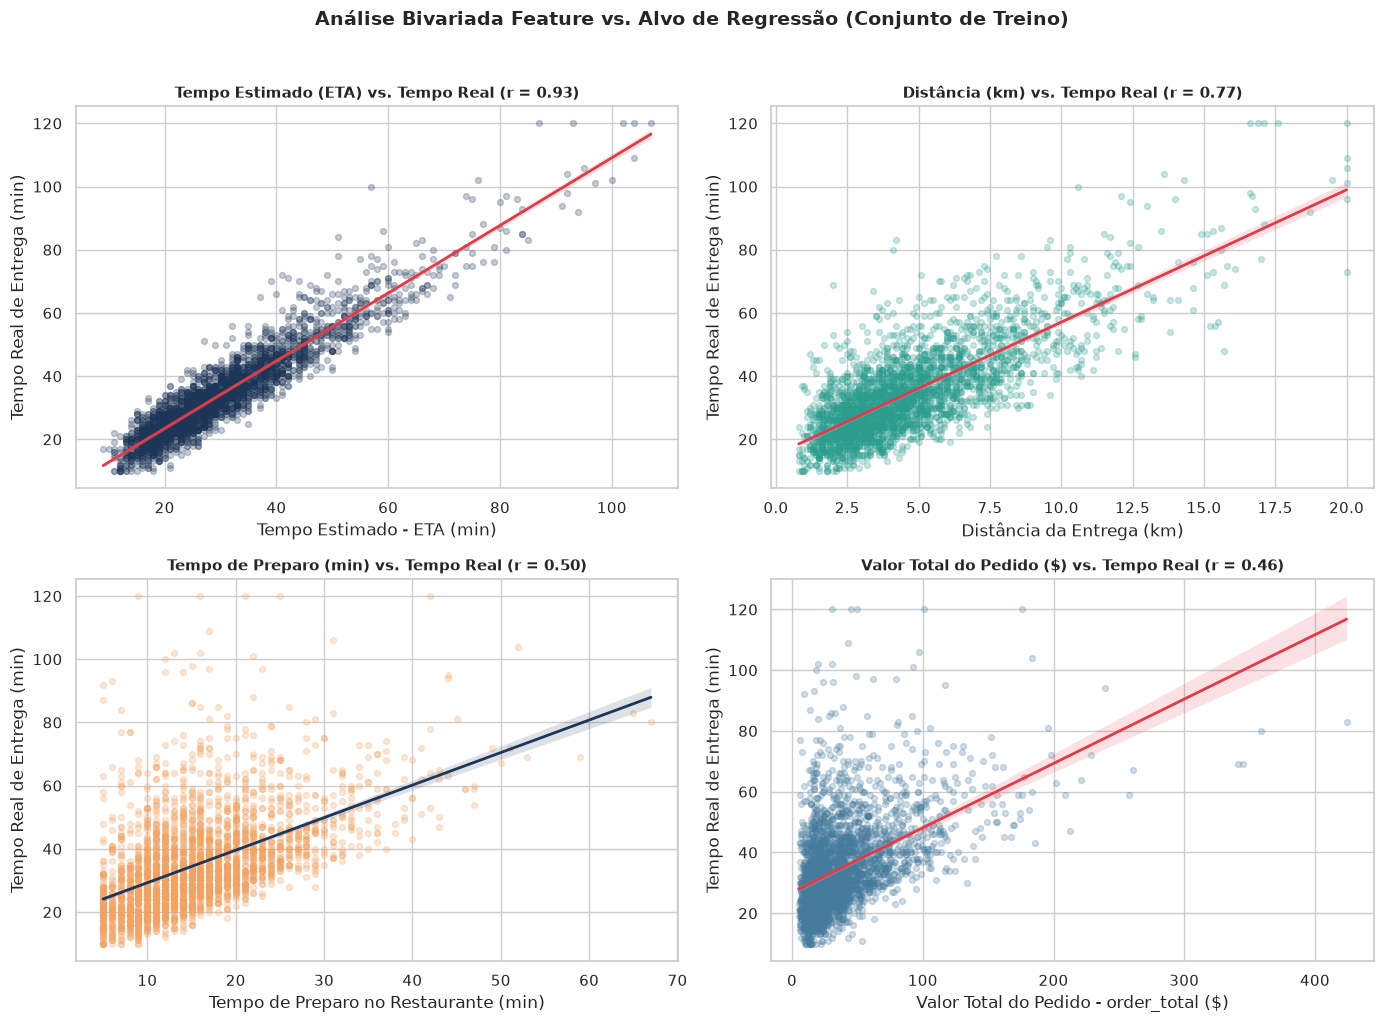

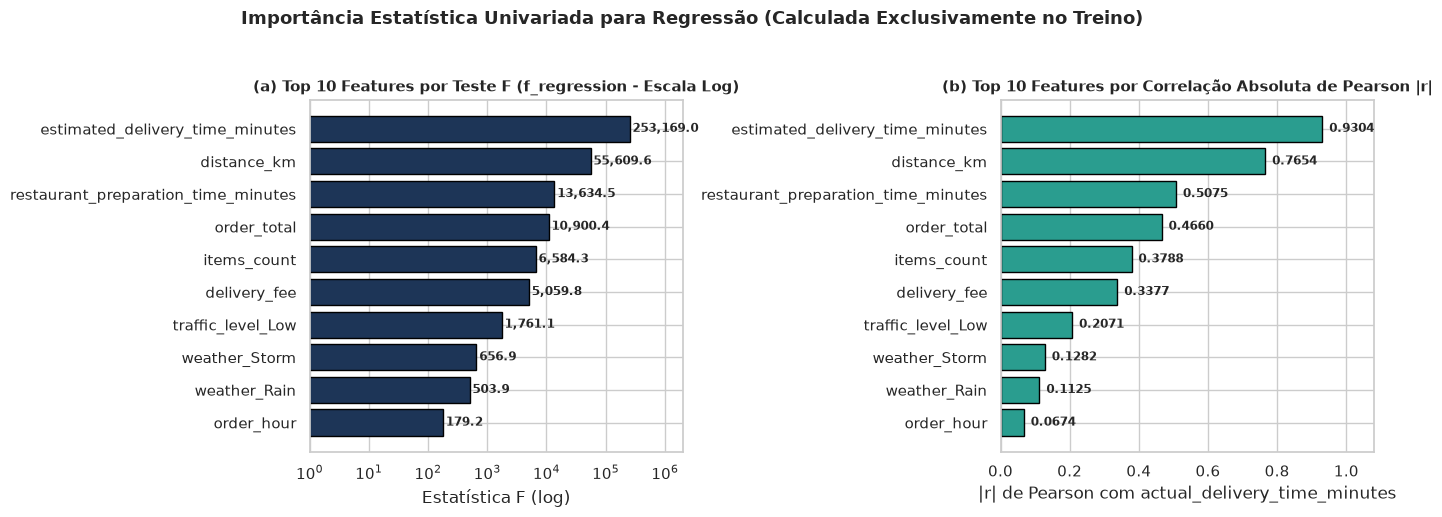

In [4]:
# Divisão Treino (80%) e Teste (20%) com semente fixa para análise sem data leakage
X_reg = df_regression.drop(columns=["actual_delivery_time_minutes"])
y_reg = df_regression["actual_delivery_time_minutes"]

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

tabela_features_reg = compute_regression_feature_stats(X_train_reg, y_train_reg)
tabela_features_reg.to_csv("../reports/tables/preprocessing_regression_features.csv", index=False)

print("=== RANKING ESTATÍSTICO DAS FEATURES PARA REGRESSÃO (NO CONJUNTO DE TREINO) ===")
display(tabela_features_reg)

# Painel gráfico: Features principais vs Alvo de Regressão (actual_delivery_time_minutes)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
amostra_reg = X_train_reg.copy()
amostra_reg["actual_delivery_time_minutes"] = y_train_reg
amostra_plot = amostra_reg.sample(n=3000, random_state=42)

# (a) estimated_delivery_time_minutes vs actual
sns.regplot(
    data=amostra_plot, x="estimated_delivery_time_minutes", y="actual_delivery_time_minutes",
    scatter_kws={"alpha": 0.25, "color": "#1d3557", "s": 18}, line_kws={"color": "#e63946", "lw": 2}, ax=axes[0, 0]
)
axes[0, 0].set_title("Tempo Estimado (ETA) vs. Tempo Real (r = 0.93)", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Tempo Estimado - ETA (min)")
axes[0, 0].set_ylabel("Tempo Real de Entrega (min)")

# (b) distance_km vs actual
sns.regplot(
    data=amostra_plot, x="distance_km", y="actual_delivery_time_minutes",
    scatter_kws={"alpha": 0.25, "color": "#2a9d8f", "s": 18}, line_kws={"color": "#e63946", "lw": 2}, ax=axes[0, 1]
)
axes[0, 1].set_title("Distância (km) vs. Tempo Real (r = 0.77)", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Distância da Entrega (km)")
axes[0, 1].set_ylabel("Tempo Real de Entrega (min)")

# (c) restaurant_preparation_time_minutes vs actual
sns.regplot(
    data=amostra_plot, x="restaurant_preparation_time_minutes", y="actual_delivery_time_minutes",
    scatter_kws={"alpha": 0.25, "color": "#f4a261", "s": 18}, line_kws={"color": "#1d3557", "lw": 2}, ax=axes[1, 0]
)
axes[1, 0].set_title("Tempo de Preparo (min) vs. Tempo Real (r = 0.50)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Tempo de Preparo no Restaurante (min)")
axes[1, 0].set_ylabel("Tempo Real de Entrega (min)")

# (d) order_total (sem redundâncias financeiras) vs actual
sns.regplot(
    data=amostra_plot, x="order_total", y="actual_delivery_time_minutes",
    scatter_kws={"alpha": 0.25, "color": "#457b9d", "s": 18}, line_kws={"color": "#e63946", "lw": 2}, ax=axes[1, 1]
)
axes[1, 1].set_title("Valor Total do Pedido ($) vs. Tempo Real (r = 0.46)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Valor Total do Pedido - order_total ($)")
axes[1, 1].set_ylabel("Tempo Real de Entrega (min)")

plt.suptitle("Análise Bivariada Feature vs. Alvo de Regressão (Conjunto de Treino)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/regression_features_vs_target.png", dpi=300, bbox_inches="tight")
plt.show()


# Gráfico de Barras Horizontais: Top 10 Features por Estatística F (f_regression) e |r| de Pearson
top10_reg = tabela_features_reg.head(10).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars_f = axes[0].barh(top10_reg["Feature"], top10_reg["Estatistica_F (f_regression)"], color="#1d3557", edgecolor="black")
axes[0].set_xscale("log")
axes[0].set_title("(a) Top 10 Features por Teste F (f_regression - Escala Log)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Estatística F (log)")
for b in bars_f:
    w = b.get_width()
    axes[0].text(w * 1.12, b.get_y() + b.get_height()/2, f"{w:,.1f}", va="center", fontsize=8.5, fontweight="bold")
axes[0].set_xlim(1, top10_reg["Estatistica_F (f_regression)"].max() * 8)

bars_r = axes[1].barh(top10_reg["Feature"], top10_reg["Correlacao_Absoluta (|r|)"], color="#2a9d8f", edgecolor="black")
axes[1].set_title("(b) Top 10 Features por Correlação Absoluta de Pearson |r|", fontsize=11, fontweight="bold")
axes[1].set_xlabel("|r| de Pearson com actual_delivery_time_minutes")
axes[1].set_xlim(0, 1.08)
for b in bars_r:
    w = b.get_width()
    axes[1].text(w + 0.02, b.get_y() + b.get_height()/2, f"{w:.4f}", va="center", fontsize=8.5, fontweight="bold")

plt.suptitle("Importância Estatística Univariada para Regressão (Calculada Exclusivamente no Treino)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("../reports/figures/preprocessing_regression_ranking.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Definição e Análise Estatística do Problema de Classificação
- **Variável Alvo Natural ($y_{\text{clf}}$):** `late_delivery` ($1 = \text{Entrega Atrasada}$, $0 = \text{Entrega No Prazo}$).
- **Correção Metodológica Importante:** Na etapa exploratória inicial da Unidade 1, havia sido criado um alvo artificial baseado na mediana do tempo de entrega (que forçava uma divisão artificial 50%/50% e dependia diretamente do alvo de regressão). Corrigimos essa escolha adotando a variável nativa do domínio logístico **`late_delivery`**, que reflete o descumprimento real do SLA prometido ao cliente em cada pedido específico (independentemente de o pedido ser curto ou longo). Naturalmente, `actual_delivery_time_minutes` é excluída das features de classificação para evitar vazamento direto do desfecho.
- **Análise de Balanceamento de Classes:**
  - Classe $0$ (*No Prazo*): **31.164 pedidos ($63{,}43\%$)**
  - Classe $1$ (*Atrasado*): **17.968 pedidos ($36{,}57\%$)**
  Trata-se de um problema com **desbalanceamento moderado** (razão aproximada de $1{,}73 : 1$). Por essa razão, a divisão Treino/Teste utiliza obrigatoriamente **amostragem estratificada (`stratify=y_clf`)**, e a avaliação dos modelos na Aula 08 prioriza **F1-score, Recall, Precision, ROC-AUC e PR-AUC** ao lado da Acurácia.
- **Testes Estatísticos Feature $\times$ Alvo (no conjunto de treino):**
  - **Teste ANOVA $F$ (`f_classif`):** Mede a separabilidade das médias das variáveis numéricas entre as classes $0$ e $1$.
  - **Teste Qui-Quadrado ($\chi^2$ - `chi2`):** Mede a dependência estatística entre as variáveis binárias/categóricas (clima, trânsito, fim de semana, tipo de cliente) e a ocorrência de atraso.

=== DISTRIBUIÇÃO E BALANCEAMENTO DE CLASSES (ESTRATIFICADO) ===


,Total_Absoluto,Total_%,Treino_Absoluto,Treino_%,Teste_Absoluto,Teste_%
0 - No Prazo,31164,63.43,24931,63.43,6233,63.43
1 - Atrasado,17968,36.57,14374,36.57,3594,36.57



=== TESTES ESTATÍSTICOS ANOVA F (f_classif) E QUI-QUADRADO (chi2) NO TREINO ===


,Feature,Tipo_Variavel,ANOVA_F (f_classif),p_valor_ANOVA,Qui_Quadrado (chi2),p_valor_Chi2
0,weather_Rain,Binaria (Dummy/Flag),3458.23,0.000000e+00,2701.16,0.000000e+00
1,restaurant_preparation_time_minutes,Continua/Discreta,2752.18,0.000000e+00,8873.80,0.000000e+00
2,weather_Storm,Binaria (Dummy/Flag),1276.38,3.973811e-275,1205.31,4.277140e-264
3,distance_km,Continua/Discreta,359.83,6.980451e-80,579.37,5.133656e-128
4,estimated_delivery_time_minutes,Continua/Discreta,297.51,2.014350e-66,1564.26,0.000000e+00
5,is_weekend,Binaria (Dummy/Flag),212.53,5.140990e-48,154.52,1.785429e-35
6,delivery_fee,Continua/Discreta,153.32,3.799277e-35,260.81,1.144301e-58
7,day_of_week_Sunday,Binaria (Dummy/Flag),144.16,3.746781e-33,124.35,7.054861e-29
8,day_of_week_Wednesday,Binaria (Dummy/Flag),98.82,2.944248e-23,82.58,1.013750e-19
9,day_of_week_Monday,Binaria (Dummy/Flag),87.33,9.662943e-21,75.60,3.479307e-18


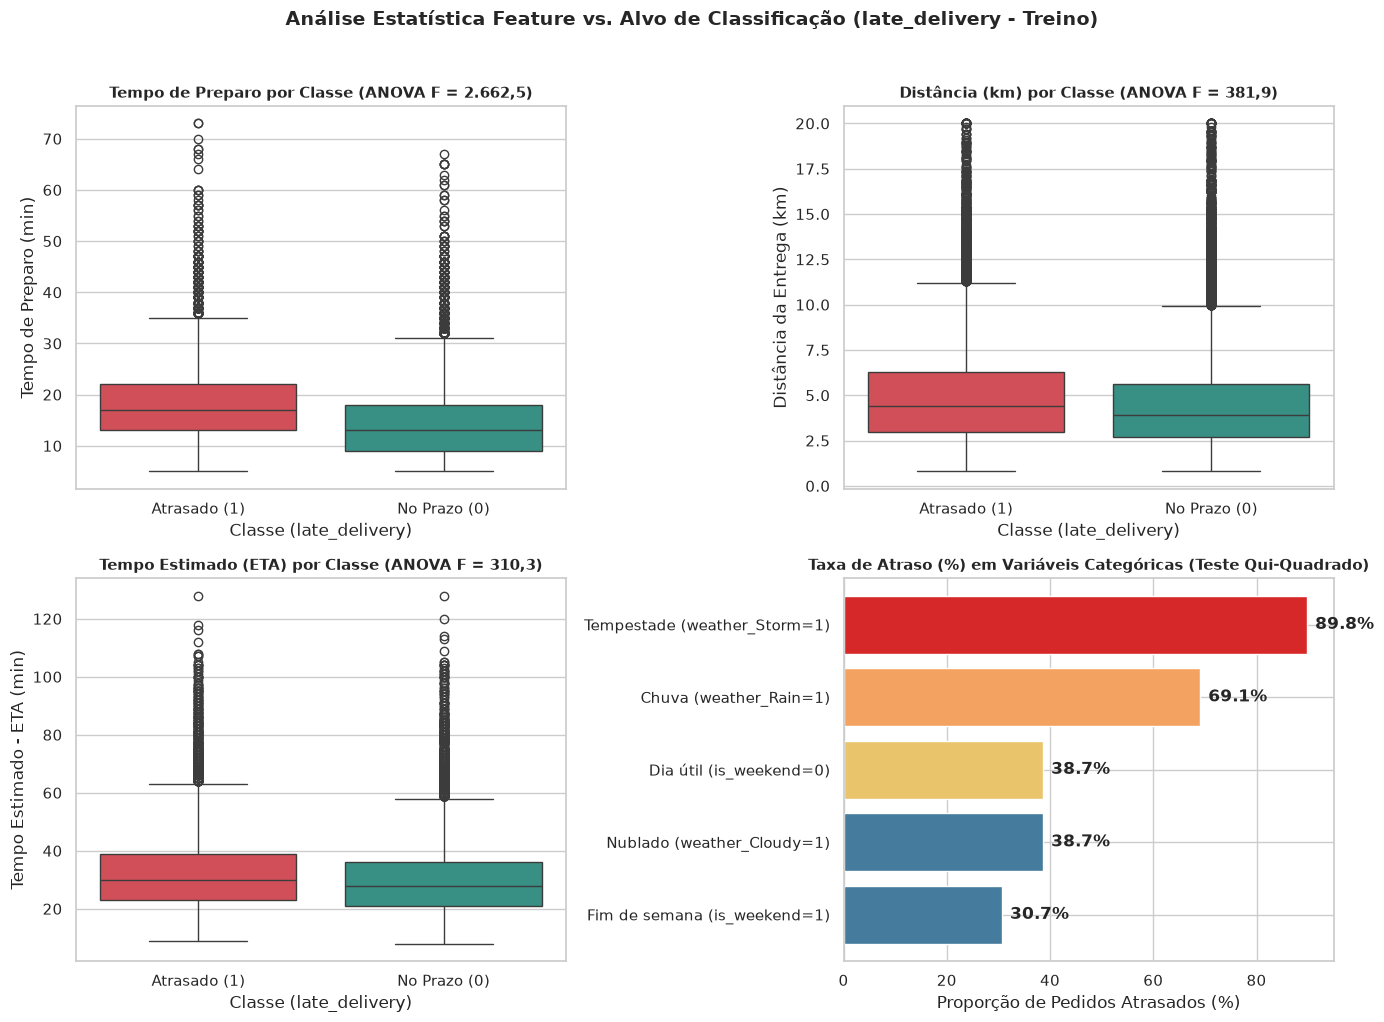

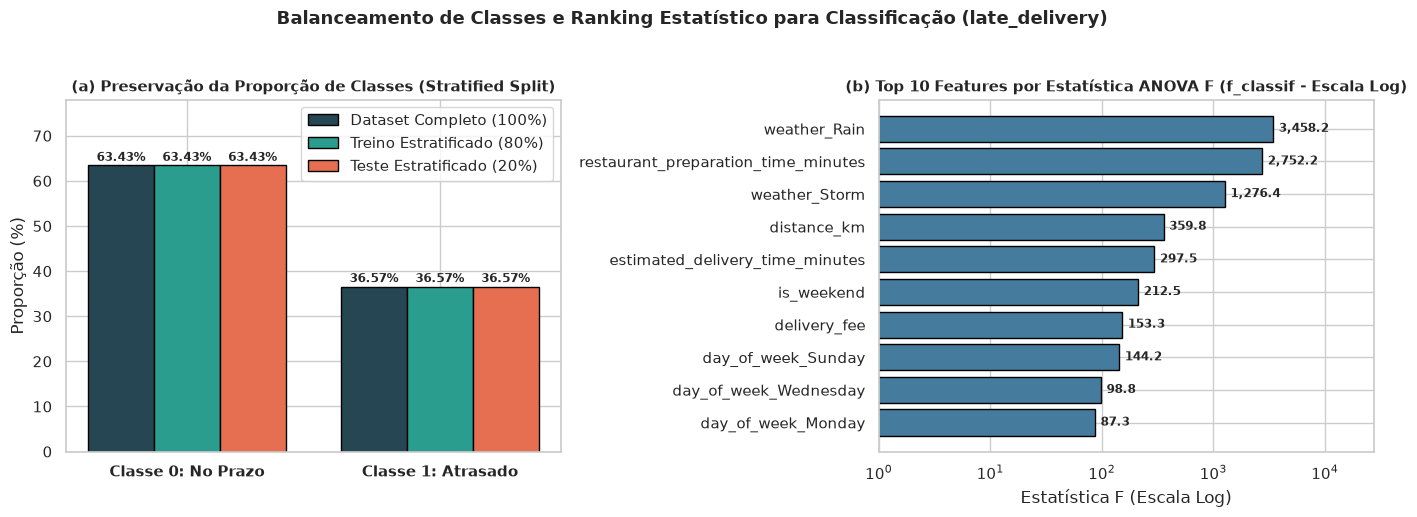

In [5]:
X_clf = df_classification.drop(columns=["late_delivery"])
y_clf = df_classification["late_delivery"]

# Divisão estratificada (80% treino / 20% teste) com semente fixa
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

# Verificação do balanceamento no Dataset Completo, Treino e Teste
bal_df = pd.DataFrame({
    "Total_Absoluto": y_clf.value_counts(),
    "Total_%": (y_clf.value_counts(normalize=True) * 100).round(2),
    "Treino_Absoluto": y_train_clf.value_counts(),
    "Treino_%": (y_train_clf.value_counts(normalize=True) * 100).round(2),
    "Teste_Absoluto": y_test_clf.value_counts(),
    "Teste_%": (y_test_clf.value_counts(normalize=True) * 100).round(2)
})
bal_df.index = ["0 - No Prazo", "1 - Atrasado"]
print("=== DISTRIBUIÇÃO E BALANCEAMENTO DE CLASSES (ESTRATIFICADO) ===")
display(bal_df)

# Tabela de ANOVA F e Qui-Quadrado no conjunto de treino
tabela_features_clf = compute_classification_feature_stats(X_train_clf, y_train_clf)
tabela_features_clf.to_csv("../reports/tables/preprocessing_classification_features.csv", index=False)

print("\n=== TESTES ESTATÍSTICOS ANOVA F (f_classif) E QUI-QUADRADO (chi2) NO TREINO ===")
display(tabela_features_clf)

# Visualização de Boxplots por Classe e Taxas de Atraso nas Features Mais Significativas
train_clf_plot = X_train_clf.copy()
train_clf_plot["Status_Entrega"] = y_train_clf.map({0: "No Prazo (0)", 1: "Atrasado (1)"})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (a) Boxplot de Tempo de Preparo por Classe
sns.boxplot(
    data=train_clf_plot, x="Status_Entrega", y="restaurant_preparation_time_minutes",
    hue="Status_Entrega", palette={"No Prazo (0)": "#2a9d8f", "Atrasado (1)": "#e63946"},
    legend=False, ax=axes[0, 0]
)
axes[0, 0].set_title("Tempo de Preparo por Classe (ANOVA F = 2.662,5)", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Classe (late_delivery)")
axes[0, 0].set_ylabel("Tempo de Preparo (min)")

# (b) Boxplot de Distância por Classe
sns.boxplot(
    data=train_clf_plot, x="Status_Entrega", y="distance_km",
    hue="Status_Entrega", palette={"No Prazo (0)": "#2a9d8f", "Atrasado (1)": "#e63946"},
    legend=False, ax=axes[0, 1]
)
axes[0, 1].set_title("Distância (km) por Classe (ANOVA F = 381,9)", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Classe (late_delivery)")
axes[0, 1].set_ylabel("Distância da Entrega (km)")

# (c) Boxplot de Tempo Estimado (ETA) por Classe
sns.boxplot(
    data=train_clf_plot, x="Status_Entrega", y="estimated_delivery_time_minutes",
    hue="Status_Entrega", palette={"No Prazo (0)": "#2a9d8f", "Atrasado (1)": "#e63946"},
    legend=False, ax=axes[1, 0]
)
axes[1, 0].set_title("Tempo Estimado (ETA) por Classe (ANOVA F = 310,3)", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Classe (late_delivery)")
axes[1, 0].set_ylabel("Tempo Estimado - ETA (min)")

# (d) Comparação da Taxa de Atraso nas Dummies de Clima e Fim de Semana (Qui-Quadrado)
taxas_dummies = pd.Series({
    "Tempestade (weather_Storm=1)": y_train_clf[X_train_clf["weather_Storm"] == 1].mean() * 100,
    "Chuva (weather_Rain=1)": y_train_clf[X_train_clf["weather_Rain"] == 1].mean() * 100,
    "Nublado (weather_Cloudy=1)": y_train_clf[X_train_clf["weather_Cloudy"] == 1].mean() * 100,
    "Dia útil (is_weekend=0)": y_train_clf[X_train_clf["is_weekend"] == 0].mean() * 100,
    "Fim de semana (is_weekend=1)": y_train_clf[X_train_clf["is_weekend"] == 1].mean() * 100,
}).sort_values(ascending=True)

bars_c = axes[1, 1].barh(taxas_dummies.index, taxas_dummies.values, color=["#457b9d", "#457b9d", "#e9c46a", "#f4a261", "#d62828"])
axes[1, 1].set_title("Taxa de Atraso (%) em Variáveis Categóricas (Teste Qui-Quadrado)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Proporção de Pedidos Atrasados (%)")
axes[1, 1].set_xlim(0, 95)
for b in bars_c:
    w = b.get_width()
    axes[1, 1].text(w + 1.5, b.get_y() + b.get_height()/2, f"{w:.1f}%", va="center", fontweight="bold")

plt.suptitle("Análise Estatística Feature vs. Alvo de Classificação (late_delivery - Treino)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/classification_features_vs_target.png", dpi=300, bbox_inches="tight")
plt.show()


# Painel Adicional: (a) Balanceamento Estratificado Treino vs Teste e (b) Top 10 Features no Teste ANOVA F (f_classif)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_pos = np.arange(2)
width = 0.26
b1 = axes[0].bar(x_pos - width, bal_df["Total_%"], width, label="Dataset Completo (100%)", color="#264653", edgecolor="black")
b2 = axes[0].bar(x_pos, bal_df["Treino_%"], width, label="Treino Estratificado (80%)", color="#2a9d8f", edgecolor="black")
b3 = axes[0].bar(x_pos + width, bal_df["Teste_%"], width, label="Teste Estratificado (20%)", color="#e76f51", edgecolor="black")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(["Classe 0: No Prazo", "Classe 1: Atrasado"], fontweight="bold")
axes[0].set_ylabel("Proporção (%)")
axes[0].set_ylim(0, 78)
axes[0].set_title("(a) Preservação da Proporção de Classes (Stratified Split)", fontsize=11, fontweight="bold")
axes[0].legend()
for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2, h + 1.0, f"{h:.2f}%", ha="center", fontsize=8.5, fontweight="bold")

top10_clf = tabela_features_clf.sort_values("ANOVA_F (f_classif)", ascending=False).head(10).iloc[::-1]
cores_teste = ["#e63946" if "Contínua" in t else "#457b9d" for t in top10_clf["Tipo_Variavel"]]
bars_stat = axes[1].barh(top10_clf["Feature"], top10_clf["ANOVA_F (f_classif)"], color=cores_teste, edgecolor="black")
axes[1].set_xscale("log")
axes[1].set_title("(b) Top 10 Features por Estatística ANOVA F (f_classif - Escala Log)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Estatística F (Escala Log)")
axes[1].set_xlim(1, top10_clf["ANOVA_F (f_classif)"].max() * 8)
for b in bars_stat:
    w = b.get_width()
    axes[1].text(w * 1.12, b.get_y() + b.get_height()/2, f"{w:,.1f}", va="center", fontsize=8.5, fontweight="bold")

plt.suptitle("Balanceamento de Classes e Ranking Estatístico para Classificação (late_delivery)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("../reports/figures/preprocessing_classification_ranking.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Padronização em *Pipeline* (Prevenção de *Data Leakage*) e Exportação dos Datasets
Para cumprir rigorosamente a diretriz da Atividade Prática:
> *"Evite data leakage: normalizações e imputações devem ser ajustadas apenas com os dados de treino (use Pipeline do scikit-learn)."*

1. Salvamos os arquivos oficiais **`../data/processed/dataset_regression.csv`** e **`../data/processed/dataset_classification.csv`** (bem como `dataset_preprocessed.csv`) com as features numéricas e dummies codificadas **em sua escala física original** (minutos, quilômetros, dólares), sem aplicar `fit_transform` na base inteira antes da divisão Treino/Teste.
2. Demonstramos e validamos abaixo a aplicação do `build_preprocessing_pipeline()` (`SimpleImputer(strategy='median')` + `StandardScaler()`), ajustado (`fit`) **exclusivamente sobre `X_train`** e aplicado via `transform` sobre `X_test`, salvando o pipeline ajustado em `../models/preprocessing_pipeline_reg.pkl` e `../models/preprocessing_pipeline_clf.pkl`.

In [6]:
# Exportação dos datasets limpos e codificados sem vazamento de escala
df_regression.to_csv("../data/processed/dataset_regression.csv", index=False)
df_classification.to_csv("../data/processed/dataset_classification.csv", index=False)
df_encoded.to_csv("../data/processed/dataset_preprocessed.csv", index=False)

# Ajuste do Pipeline de pré-processamento APENAS nos conjuntos de treino
pipe_reg = build_preprocessing_pipeline()
X_train_reg_scaled = pipe_reg.fit_transform(X_train_reg)
X_test_reg_scaled = pipe_reg.transform(X_test_reg)

pipe_clf = build_preprocessing_pipeline()
X_train_clf_scaled = pipe_clf.fit_transform(X_train_clf)
X_test_clf_scaled = pipe_clf.transform(X_test_clf)

joblib.dump(pipe_reg, "../models/preprocessing_pipeline_reg.pkl")
joblib.dump(pipe_clf, "../models/preprocessing_pipeline_clf.pkl")

print("Arquivos exportados em '../data/processed/':")
print(f" - dataset_clean.csv:          {df_limpo.shape[0]:,} linhas x {df_limpo.shape[1]} colunas")
print(f" - dataset_regression.csv:     {df_regression.shape[0]:,} linhas x {df_regression.shape[1]} colunas")
print(f" - dataset_classification.csv: {df_classification.shape[0]:,} linhas x {df_classification.shape[1]} colunas")
print(f" - dataset_preprocessed.csv:   {df_encoded.shape[0]:,} linhas x {df_encoded.shape[1]} colunas")
print("\nVerificação de ausência de Data Leakage no StandardScaler (Regressão):")
print(f" - Média das features no Treino escalonado (deve ser ~0.0): {np.abs(X_train_reg_scaled.mean(axis=0)).max():.6f}")
print(f" - Desvio padrão no Treino escalonado (deve ser ~1.0):      {np.abs(X_train_reg_scaled.std(axis=0) - 1.0).max():.6f}")
print(f" - Média das features no Teste escalonado (usando mu_treino): {np.abs(X_test_reg_scaled.mean(axis=0)).max():.4f}")


Arquivos exportados em '../data/processed/':
 - dataset_clean.csv:          49,132 linhas x 36 colunas
 - dataset_regression.csv:     49,132 linhas x 27 colunas
 - dataset_classification.csv: 49,132 linhas x 27 colunas
 - dataset_preprocessed.csv:   49,132 linhas x 28 colunas

Verificação de ausência de Data Leakage no StandardScaler (Regressão):
 - Média das features no Treino escalonado (deve ser ~0.0): 0.000000
 - Desvio padrão no Treino escalonado (deve ser ~1.0):      0.000000
 - Média das features no Teste escalonado (usando mu_treino): 0.0189
